<a href="https://colab.research.google.com/github/ramahhdk87654321-bit/AI_LAB_PROJECT/blob/main/AI_LAB_PROJECT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Importing libraries**

In [1]:
!pip install gradio -q

In [2]:
# 1. General Libraries
import re
import warnings
import copy
import json
import os
import html

from collections import Counter

# 2. Data Processing
import numpy as np
import pandas as pd

# 3. Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# 4. PyTorch
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader

# 5. Scikit-learn
from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# 6. Progress Bar
from tqdm import tqdm

# 7. Demo Interface
import gradio as gr

# 8. Warning Settings
warnings.filterwarnings("ignore")

# 9. Device Configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch Version:", torch.__version__)
print("Available Device:", device)

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))

PyTorch Version: 2.14.1+cu130
Available Device: cuda
GPU Name: Tesla T4


# **Loading the Dataset**

In [3]:
!pip install -q gdown

import gdown
import pandas as pd

file_id = "1sctiG9bSE_Ien3q5H4G5hcedqRsiFPWX"
url = f"https://drive.google.com/uc?id={file_id}"

gdown.download(url, "IMDB Dataset.csv", quiet=False)

df = pd.read_csv("IMDB Dataset.csv")


Downloading...
From: https://drive.google.com/uc?id=1sctiG9bSE_Ien3q5H4G5hcedqRsiFPWX
To: /content/IMDB Dataset.csv
100%|██████████| 66.2M/66.2M [00:01<00:00, 57.9MB/s]


# **Exploratory Data Analysis (EDA)**

In [4]:
print("Shape:", df.shape)
print("Columns:", list(df.columns))
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicated rows:", df.duplicated().sum())

Shape: (50000, 2)
Columns: ['review', 'sentiment']

Missing values:
 review       0
sentiment    0
dtype: int64

Duplicated rows: 418


sentiment
positive    25000
negative    25000
Name: count, dtype: int64


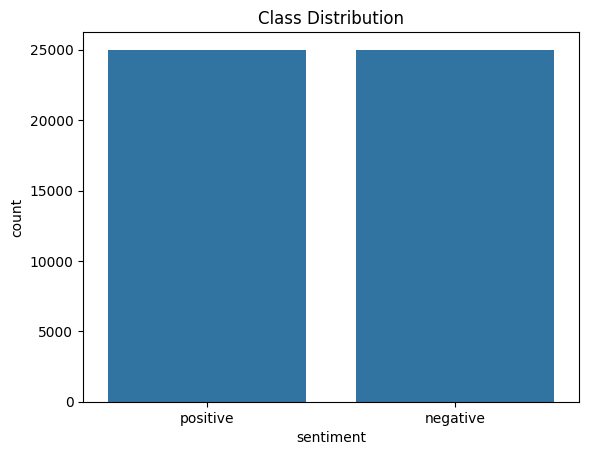

In [5]:
# Class distribution
print(df["sentiment"].value_counts())

sns.countplot(x="sentiment", data=df)
plt.title("Class Distribution")
plt.show()

count    50000.000000
mean       231.156940
std        171.343997
min          4.000000
25%        126.000000
50%        173.000000
75%        280.000000
max       2470.000000
Name: length, dtype: float64


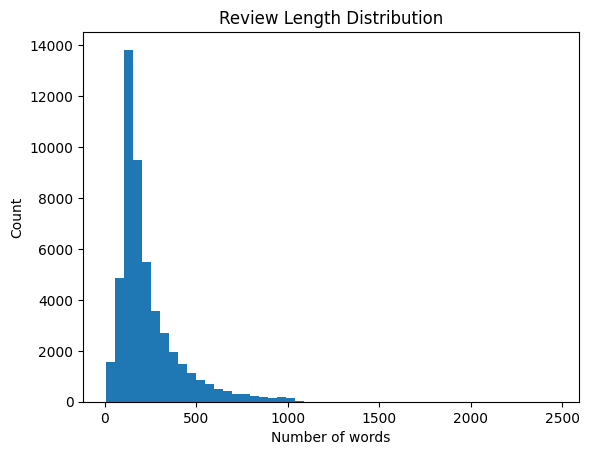

In [6]:
# Review length (number of words)
df["length"] = df["review"].apply(lambda x: len(x.split()))
print(df["length"].describe())

plt.hist(df["length"], bins=50)
plt.title("Review Length Distribution")
plt.xlabel("Number of words")
plt.ylabel("Count")
plt.show()

# **Text Cleaning**

In [7]:
df = df.drop_duplicates().reset_index(drop=True)

def clean_text(text):
    # Convert HTML entities and lowercase
    text = html.unescape(str(text)).lower()

    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Normalize apostrophes
    text = text.replace("’", "'")

    # Keep English letters, apostrophes, and spaces
    text = re.sub(r"[^a-z'\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

df["clean_review"] = df["review"].apply(clean_text)
df["label"] = df["sentiment"].map({"negative": 0, "positive": 1})

print("Before:", df["review"][0][:150])
print("After :", df["clean_review"][0][:150])


Before: One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with
After : one of the other reviewers has mentioned that after watching just oz episode you'll be hooked they are right as this is exactly what happened with me 


# **Splitting the Data (Train / Validation / Test)**

In [8]:
train_df, temp_df = train_test_split(df, test_size=0.30, random_state=42, stratify=df["label"])
val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=42, stratify=temp_df["label"])

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 34707
Validation: 7437
Test: 7438


# **Tokenization**

In [9]:
def tokenize(text):
    return text.split()

# Count words in the training set only
counter = Counter()
for text in train_df["clean_review"]:
    counter.update(tokenize(text))

# Build the vocabulary (<PAD> = 0, <UNK> = 1)
VOCAB_SIZE = 10000
vocab = {"<PAD>": 0, "<UNK>": 1}
for i, (word, _) in enumerate(counter.most_common(VOCAB_SIZE - 2), start=2):
    vocab[word] = i

print("Vocabulary size:", len(vocab))

# Convert text to numbers
def encode(text):
    return [vocab.get(word, 1) for word in tokenize(text)]

print(encode("this movie was great"))

Vocabulary size: 10000
[11, 15, 13, 80]


# **Padding**

In [10]:
MAX_LEN = 300

def pad_sequence(seq, max_len=MAX_LEN):
    if len(seq) >= max_len:
        return seq[:max_len]                   # cut long reviews
    # return [0] * (max_len - len(seq)) + seq    # pad short reviews
    return seq + [0] * (max_len - len(seq))

def prepare(data):
    X = np.array([pad_sequence(encode(t)) for t in data["clean_review"]])
    y = data["label"].values
    return X, y

X_train, y_train = prepare(train_df)
X_val, y_val = prepare(val_df)
X_test, y_test = prepare(test_df)

print("X_train:", X_train.shape)
print("X_val  :", X_val.shape)
print("X_test :", X_test.shape)

X_train: (34707, 300)
X_val  : (7437, 300)
X_test : (7438, 300)


# **PyTorch Dataset & DataLoader**

In [11]:
class IMDBDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.long)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

BATCH_SIZE = 64

train_loader = DataLoader(IMDBDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(IMDBDataset(X_val, y_val), batch_size=BATCH_SIZE)
test_loader = DataLoader(IMDBDataset(X_test, y_test), batch_size=BATCH_SIZE)

# Check one batch
x_batch, y_batch = next(iter(train_loader))
print("x_batch:", x_batch.shape)
print("y_batch:", y_batch.shape)

x_batch: torch.Size([64, 300])
y_batch: torch.Size([64])


In [12]:
print("Train X:", X_train.shape)
print("Train y:", y_train.shape)

print("Validation X:", X_val.shape)
print("Validation y:", y_val.shape)

print("Test X:", X_test.shape)
print("Test y:", y_test.shape)

x_batch, y_batch = next(iter(train_loader))

print("Batch X:", x_batch.shape)
print("Batch y:", y_batch.shape)

print("X dtype:", x_batch.dtype)
print("y dtype:", y_batch.dtype)

Train X: (34707, 300)
Train y: (34707,)
Validation X: (7437, 300)
Validation y: (7437,)
Test X: (7438, 300)
Test y: (7438,)
Batch X: torch.Size([64, 300])
Batch y: torch.Size([64])
X dtype: torch.int64
y dtype: torch.float32


# **GRU Model Development and Training**  

This section focuses on building, training, and evaluating a Gated Recurrent Unit (GRU) model for IMDB movie review sentiment classification.:

In [13]:
# Check available device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch Version:", torch.__version__)
print("Available Device:", device)

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))

PyTorch Version: 2.14.1+cu130
Available Device: cuda
GPU Name: Tesla T4


## 1. GRU Model Configuration

In this section, we define the hyperparameters that control the GRU architecture and training process.

In [14]:
# Model Hyperparameters

VOCAB_SIZE = len(vocab)

EMBEDDING_DIM = 128
HIDDEN_DIM = 128
NUM_LAYERS = 1
DROPOUT = 0.3

# Training Hyperparameters
LEARNING_RATE = 0.001
EPOCHS = 10
BATCH_SIZE = 64

print("Vocabulary Size:", VOCAB_SIZE)
print("Embedding Dimension:", EMBEDDING_DIM)
print("Hidden Dimension:", HIDDEN_DIM)
print("Number of GRU Layers:", NUM_LAYERS)
print("Dropout:", DROPOUT)
print("Learning Rate:", LEARNING_RATE)
print("Epochs:", EPOCHS)
print("Batch Size:", BATCH_SIZE)


Vocabulary Size: 10000
Embedding Dimension: 128
Hidden Dimension: 128
Number of GRU Layers: 1
Dropout: 0.3
Learning Rate: 0.001
Epochs: 10
Batch Size: 64


### 2. Building the GRU Model Architecture

The GRU model consists of an Embedding Layer, a Gated Recurrent Unit (GRU) Layer, a Dropout Layer, and a Fully Connected Output Layer.

In [15]:
class GRUClassifier(nn.Module):

    def __init__(self, vocab_size, embedding_dim, hidden_dim,
                 num_layers, dropout):

        super(GRUClassifier, self).__init__()

        # Embedding Layer
        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=0
        )


#### 3. GRU Layer

The GRU Layer processes the embedded word sequences and captures contextual information using its hidden states and gating mechanisms.

In [16]:
class GRUClassifier(nn.Module):

    def __init__(self, vocab_size, embedding_dim, hidden_dim,
                 num_layers, dropout):

        super(GRUClassifier, self).__init__()

        # Embedding Layer
        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=0
        )

        # GRU Layer
        self.gru = nn.GRU(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0
        )

        # Dropout Layer
        self.dropout = nn.Dropout(dropout)

        # Fully Connected Layer
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):

        # Calculate actual review lengths
        lengths = (x != 0).sum(dim=1).clamp(min=1)

        # Embedding
        embedded = self.embedding(x)

        # Pack sequences to ignore padding
        packed_embedded = nn.utils.rnn.pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        # GRU
        packed_output, hidden = self.gru(packed_embedded)

        # Get the final hidden state
        final_hidden = hidden[-1]

        # Dropout
        dropped = self.dropout(final_hidden)

        # Fully Connected Layer
        output = self.fc(dropped)

        return output.squeeze(1)


In [17]:
model = GRUClassifier(
    vocab_size=VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
    dropout=DROPOUT
).to(device)

print(model)


GRUClassifier(
  (embedding): Embedding(10000, 128, padding_idx=0)
  (gru): GRU(128, 128, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)


### 4. Testing the GRU Model

Before training, we perform a forward pass using one batch to verify the model architecture and output dimensions.

In [18]:
# Get one batch
x_batch, y_batch = next(iter(train_loader))

# Move input to the selected device
x_batch = x_batch.to(device)

# Set model to evaluation mode
model.eval()

# Perform forward pass
with torch.no_grad():
    outputs = model(x_batch)

print("Input Shape:", x_batch.shape)
print("Output Shape:", outputs.shape)
print("Sample Outputs:", outputs[:5])


Input Shape: torch.Size([64, 300])
Output Shape: torch.Size([64])
Sample Outputs: tensor([ 0.1533,  0.2361,  0.1207,  0.2296, -0.0269], device='cuda:0')


### 5. Loss Function and Optimizer

In this section, we define the loss function and optimizer used to train the GRU model.

In [19]:
# Define Loss Function
criterion = nn.BCEWithLogitsLoss()

# Define Optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

print("Loss Function:", criterion)
print("Optimizer:", optimizer)


Loss Function: BCEWithLogitsLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


### 6. Training the GRU Model

The training process updates the model parameters using batches of training data over multiple epochs. The model learns to minimize the classification loss through backpropagation and optimization.

In [20]:
def train_one_epoch(model, train_loader, criterion, optimizer, device):

    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for x_batch, y_batch in train_loader:

        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        # Forward Pass
        outputs = model(x_batch)

        # Calculate Loss
        loss = criterion(outputs, y_batch)

        # Calculate Accuracy
        predictions = (outputs >= 0).float()

        correct += (predictions == y_batch).sum().item()
        total += y_batch.size(0)

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)
    accuracy = correct / total

    return average_loss, accuracy

#### 7. Validation Function

This function evaluates the model on the validation dataset without updating its parameters. It calculates the average validation loss to monitor the model's performance during training.

In [21]:
def evaluate(model, data_loader, criterion, device):

    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for x_batch, y_batch in data_loader:

            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)

            # Forward Pass
            outputs = model(x_batch)

            # Calculate Loss
            loss = criterion(outputs, y_batch)

            total_loss += loss.item() * x_batch.size(0)

            # Calculate Accuracy
            predictions = (outputs >= 0).float()

            correct += (predictions == y_batch).sum().item()
            total += y_batch.size(0)

    average_loss = total_loss / len(data_loader.dataset)
    accuracy = correct / total

    return average_loss, accuracy

In [22]:
import copy

# Store training history
train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

# Track the best model
best_val_loss = float("inf")
best_model_state = None

# Training Loop
for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    val_loss, val_acc = evaluate(
        model, val_loader, criterion, device
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    # Save the best model
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = copy.deepcopy(model.state_dict())

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Validation Loss: {val_loss:.4f} "
        f"| Train Accuracy: {train_acc:.4f} "
        f"| Validation Accuracy: {val_acc:.4f}"
    )

# Load the best model
model.load_state_dict(best_model_state)

print("\nTraining Completed!")
print(f"Best Validation Loss: {best_val_loss:.4f}")

Epoch [1/10] | Train Loss: 0.5850 | Validation Loss: 0.4545 | Train Accuracy: 0.6827 | Validation Accuracy: 0.7988
Epoch [2/10] | Train Loss: 0.3432 | Validation Loss: 0.2993 | Train Accuracy: 0.8556 | Validation Accuracy: 0.8798
Epoch [3/10] | Train Loss: 0.2485 | Validation Loss: 0.2764 | Train Accuracy: 0.9019 | Validation Accuracy: 0.8889
Epoch [4/10] | Train Loss: 0.1934 | Validation Loss: 0.2740 | Train Accuracy: 0.9277 | Validation Accuracy: 0.8914
Epoch [5/10] | Train Loss: 0.1481 | Validation Loss: 0.2974 | Train Accuracy: 0.9459 | Validation Accuracy: 0.8896
Epoch [6/10] | Train Loss: 0.1033 | Validation Loss: 0.3374 | Train Accuracy: 0.9672 | Validation Accuracy: 0.8888
Epoch [7/10] | Train Loss: 0.0695 | Validation Loss: 0.3892 | Train Accuracy: 0.9778 | Validation Accuracy: 0.8903
Epoch [8/10] | Train Loss: 0.0485 | Validation Loss: 0.4739 | Train Accuracy: 0.9842 | Validation Accuracy: 0.8827
Epoch [9/10] | Train Loss: 0.0341 | Validation Loss: 0.5054 | Train Accuracy: 0.

In [23]:
all_predictions = []
all_labels = []

model.eval()

with torch.no_grad():

    for x_batch, y_batch in test_loader:

        x_batch = x_batch.to(device)

        # Forward Pass
        outputs = model(x_batch)

        # Convert logits to probabilities
        probabilities = torch.sigmoid(outputs)

        # Convert probabilities to class predictions
        predictions = (probabilities >= 0.5).long()

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(y_batch.cpu().numpy())

y_pred = np.array(all_predictions)
y_true = np.array(all_labels)

print("Predictions Shape:", y_pred.shape)
print("Actual Labels Shape:", y_true.shape)

print("\nFirst 10 Predictions:", y_pred[:10])
print("First 10 Actual Labels:", y_true[:10])

Predictions Shape: (7438,)
Actual Labels Shape: (7438,)

First 10 Predictions: [1 1 1 1 0 1 1 0 0 1]
First 10 Actual Labels: [1. 1. 1. 1. 0. 1. 1. 0. 0. 1.]


In [24]:
# Save model checkpoint
checkpoint = {
    "model_state_dict": model.state_dict(),
    "vocab_size": VOCAB_SIZE,
    "embedding_dim": EMBEDDING_DIM,
    "hidden_dim": HIDDEN_DIM,
    "num_layers": NUM_LAYERS,
    "dropout": DROPOUT,
    "max_len": MAX_LEN
}

torch.save(checkpoint, "gru_model.pth")

# Save vocabulary separately
with open("vocab.json", "w", encoding="utf-8") as f:
    json.dump(vocab, f, ensure_ascii=False)

print("GRU model and vocabulary saved successfully!")

GRU model and vocabulary saved successfully!


In [25]:
from google.colab import files

files.download("gru_model.pth")
files.download("vocab.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(y_true, y_pred)

recall = recall_score(y_true, y_pred)

f1 = f1_score(y_true, y_pred)

# Print results
print("GRU Model Evaluation Results")
print("-----------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

# Detailed classification report
print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Negative", "Positive"]
))

GRU Model Evaluation Results
-----------------------------
Accuracy:  0.8899
Precision: 0.8723
Recall:    0.9145
F1-Score:  0.8929

Classification Report:
              precision    recall  f1-score   support

    Negative       0.91      0.87      0.89      3705
    Positive       0.87      0.91      0.89      3733

    accuracy                           0.89      7438
   macro avg       0.89      0.89      0.89      7438
weighted avg       0.89      0.89      0.89      7438



In [27]:
# Save GRU results before training LSTM

gru_accuracy = accuracy
gru_precision = precision
gru_recall = recall
gru_f1 = f1

# Save GRU model parameters count
gru_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("GRU Results Saved Successfully!")
print("GRU Accuracy:", gru_accuracy)
print("GRU F1-Score:", gru_f1)
print("GRU Parameters:", gru_params)

GRU Results Saved Successfully!
GRU Accuracy: 0.8898897553105674
GRU F1-Score: 0.8928991761475088
GRU Parameters: 1379201


# *LSTM Hyperparameters*

# *Building LSTM Model Architecture*

In [28]:
class LSTMClassifier(nn.Module):

    def __init__(self, vocab_size, embedding_dim, hidden_dim,
                 num_layers, dropout):

        super(LSTMClassifier, self).__init__()

        # Embedding Layer --> to convert words to vectors
        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=0
        )

        # LSTM Layer -->To understand word sequences.
        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0
        )

        # Dropout Layer -->To reduce Overfitting
        self.dropout = nn.Dropout(dropout)

        # Fully Connected Layer -->For classification
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):

        # Calculate actual review lengths
        lengths = (x != 0).sum(dim=1).clamp(min=1)

        # Embedding
        embedded = self.embedding(x)

        # Pack sequences to ignore padding
        packed_embedded = nn.utils.rnn.pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        # LSTM
        packed_output, (hidden, cell) = self.lstm(
            packed_embedded
        )

        # Get the final hidden state
        final_hidden = hidden[-1]

        # Dropout
        dropped = self.dropout(final_hidden)

        # Fully Connected Layer
        output = self.fc(dropped)

        return output.squeeze(1)

# *Initialize LSTM Model*

In [29]:
#Here we create the model and transfer it to the GPU or CPU depending on the available hardware.
lstm_model = LSTMClassifier(
    vocab_size=VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
    dropout=DROPOUT
).to(device)

print(lstm_model)

LSTMClassifier(
  (embedding): Embedding(10000, 128, padding_idx=0)
  (lstm): LSTM(128, 128, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)


# *Testing LSTM Model*

In [30]:
#Before training, we make sure that the model receives the data and outputs the results correctly.
# Get one batch
x_batch, y_batch = next(iter(train_loader))

x_batch = x_batch.to(device)

# Set model to evaluation mode
lstm_model.eval()

with torch.no_grad():

    outputs = lstm_model(x_batch)

print("Input Shape:", x_batch.shape)
print("Output Shape:", outputs.shape)
print("Sample Outputs:", outputs[:5])

Input Shape: torch.Size([64, 300])
Output Shape: torch.Size([64])
Sample Outputs: tensor([ 0.0064, -0.0019, -0.0379,  0.0384, -0.0418], device='cuda:0')


# *Loss Function and Optimizer*

In [31]:
#We will use the same Loss Function and Optimizer used in the GRU.
# Loss Function
lstm_criterion = nn.BCEWithLogitsLoss()

# Optimizer
lstm_optimizer = optim.Adam(
    lstm_model.parameters(),
    lr=LEARNING_RATE
)

print("Loss Function:", lstm_criterion)
print("Optimizer:", lstm_optimizer)

Loss Function: BCEWithLogitsLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


# *Training LSTM Mode*

In [32]:
import time
import copy

# Store training history
lstm_train_losses = []
lstm_val_losses = []

lstm_train_accuracies = []
lstm_val_accuracies = []

# Track the best model
best_lstm_val_loss = float("inf")
best_lstm_state = None

# Start Training Time
lstm_start_time = time.time()

# Training Loop
for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        lstm_model,
        train_loader,
        lstm_criterion,
        lstm_optimizer,
        device
    )

    val_loss, val_acc = evaluate(
        lstm_model,
        val_loader,
        lstm_criterion,
        device
    )

    lstm_train_losses.append(train_loss)
    lstm_val_losses.append(val_loss)

    lstm_train_accuracies.append(train_acc)
    lstm_val_accuracies.append(val_acc)

    # Save best model
    if val_loss < best_lstm_val_loss:

        best_lstm_val_loss = val_loss

        best_lstm_state = copy.deepcopy(
            lstm_model.state_dict()
        )

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Validation Loss: {val_loss:.4f} "
        f"| Train Accuracy: {train_acc:.4f} "
        f"| Validation Accuracy: {val_acc:.4f}"
    )

# Calculate Training Time
lstm_training_time = time.time() - lstm_start_time

# Load Best Model
lstm_model.load_state_dict(best_lstm_state)

print("\nLSTM Training Completed!")
print("Best Validation Loss:", best_lstm_val_loss)
print("Training Time:", round(lstm_training_time, 2), "seconds")

Epoch [1/10] | Train Loss: 0.6188 | Validation Loss: 0.5621 | Train Accuracy: 0.6506 | Validation Accuracy: 0.7152
Epoch [2/10] | Train Loss: 0.5263 | Validation Loss: 0.4466 | Train Accuracy: 0.7396 | Validation Accuracy: 0.7999
Epoch [3/10] | Train Loss: 0.3938 | Validation Loss: 0.4046 | Train Accuracy: 0.8303 | Validation Accuracy: 0.8213
Epoch [4/10] | Train Loss: 0.4850 | Validation Loss: 0.4230 | Train Accuracy: 0.7622 | Validation Accuracy: 0.8190
Epoch [5/10] | Train Loss: 0.4214 | Validation Loss: 0.4441 | Train Accuracy: 0.8154 | Validation Accuracy: 0.8092
Epoch [6/10] | Train Loss: 0.3403 | Validation Loss: 0.3388 | Train Accuracy: 0.8579 | Validation Accuracy: 0.8546
Epoch [7/10] | Train Loss: 0.2818 | Validation Loss: 0.3425 | Train Accuracy: 0.8861 | Validation Accuracy: 0.8541
Epoch [8/10] | Train Loss: 0.2733 | Validation Loss: 0.3128 | Train Accuracy: 0.8925 | Validation Accuracy: 0.8713
Epoch [9/10] | Train Loss: 0.2154 | Validation Loss: 0.3103 | Train Accuracy: 0.

# *Evaluating LSTM Model*

In [33]:
# Store predictions and actual labels
lstm_predictions = []
lstm_labels = []

lstm_model.eval()

with torch.no_grad():

    for x_batch, y_batch in test_loader:

        x_batch = x_batch.to(device)

        # Forward Pass
        outputs = lstm_model(x_batch)

        # Convert logits to probabilities
        probabilities = torch.sigmoid(outputs)

        # Convert probabilities to predictions
        predictions = (probabilities >= 0.5).long()

        lstm_predictions.extend(
            predictions.cpu().numpy()
        )

        lstm_labels.extend(
            y_batch.cpu().numpy()
        )

# Convert to NumPy arrays
lstm_y_pred = np.array(lstm_predictions)
lstm_y_true = np.array(lstm_labels).astype(int)

print("Predictions Shape:", lstm_y_pred.shape)
print("Actual Labels Shape:", lstm_y_true.shape)

print("First 10 Predictions:", lstm_y_pred[:10])
print("First 10 Actual Labels:", lstm_y_true[:10])

Predictions Shape: (7438,)
Actual Labels Shape: (7438,)
First 10 Predictions: [1 1 1 1 0 1 1 0 0 1]
First 10 Actual Labels: [1 1 1 1 0 1 1 0 0 1]


# *Calculate Evaluation Metrics*

In [34]:
# Calculate Metrics

lstm_accuracy = accuracy_score(
    lstm_y_true, lstm_y_pred
)

lstm_precision = precision_score(
    lstm_y_true, lstm_y_pred
)

lstm_recall = recall_score(
    lstm_y_true, lstm_y_pred
)

lstm_f1 = f1_score(
    lstm_y_true, lstm_y_pred
)

# Print Results
print("LSTM Model Evaluation Results")
print("------------------------------")

print(f"Accuracy:  {lstm_accuracy:.4f}")
print(f"Precision: {lstm_precision:.4f}")
print(f"Recall:    {lstm_recall:.4f}")
print(f"F1-Score:  {lstm_f1:.4f}")

# Classification Report
print("\nClassification Report:")

print(classification_report(
    lstm_y_true,
    lstm_y_pred,
    target_names=["Negative", "Positive"]
))

LSTM Model Evaluation Results
------------------------------
Accuracy:  0.8822
Precision: 0.8889
Recall:    0.8746
F1-Score:  0.8817

Classification Report:
              precision    recall  f1-score   support

    Negative       0.88      0.89      0.88      3705
    Positive       0.89      0.87      0.88      3733

    accuracy                           0.88      7438
   macro avg       0.88      0.88      0.88      7438
weighted avg       0.88      0.88      0.88      7438



In [35]:
print("LSTM Train Losses:", lstm_train_losses)
print("LSTM Validation Losses:", lstm_val_losses)
print("Best LSTM Validation Loss:", best_lstm_val_loss)

LSTM Train Losses: [0.6188414704404483, 0.5262586265857268, 0.39381793827422196, 0.48495837746952997, 0.42144751696955435, 0.3403003867818506, 0.28178298069956553, 0.27326222142791223, 0.21544018385050265, 0.1836929374732914]
LSTM Validation Losses: [0.562060075829198, 0.4465689472578635, 0.40457870358899506, 0.4230264097079484, 0.4441438012803869, 0.3388022485761308, 0.34247423867528853, 0.3128011963477102, 0.3103221157284951, 0.30624555232256545]
Best LSTM Validation Loss: 0.30624555232256545


# *Save LSTM Model*

In [36]:
# Save LSTM Model Checkpoint

lstm_checkpoint = {
    "model_state_dict": lstm_model.state_dict(),
    "vocab_size": VOCAB_SIZE,
    "embedding_dim": EMBEDDING_DIM,
    "hidden_dim": HIDDEN_DIM,
    "num_layers": NUM_LAYERS,
    "dropout": DROPOUT,
    "max_len": MAX_LEN
}

torch.save(
    lstm_checkpoint,
    "lstm_model.pth"
)

print("LSTM Model Saved Successfully!")

LSTM Model Saved Successfully!


# *GRU vs LSTM Comparison*

In [37]:
# Count Trainable Parameters

lstm_params = sum(
    p.numel()
    for p in lstm_model.parameters()
    if p.requires_grad
)

# Create Comparison Table

comparison_df = pd.DataFrame({

    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "Training Time (seconds)",
        "Trainable Parameters"
    ],

    "GRU": [
        gru_accuracy,
        gru_precision,
        gru_recall,
        gru_f1,
        np.nan,  # GRU training time was not recorded
        gru_params
    ],

    "LSTM": [
        lstm_accuracy,
        lstm_precision,
        lstm_recall,
        lstm_f1,
        lstm_training_time,
        lstm_params
    ]

})

print("GRU vs LSTM Comparison")
display(comparison_df.round(4))

GRU vs LSTM Comparison


,Metric,GRU,LSTM
0,Accuracy,8.899000e-01,8.822000e-01
1,Precision,8.723000e-01,8.889000e-01
2,Recall,9.145000e-01,8.746000e-01
3,F1-Score,8.929000e-01,8.817000e-01
4,Training Time (seconds),NaN,1.026360e+02
5,Trainable Parameters,1.379201e+06,1.412225e+06


# *Determine the Best Model*

In [38]:
print("Model Performance Comparison")
print("----------------------------")

if gru_accuracy > lstm_accuracy:

    print("GRU achieved higher Accuracy.")

elif lstm_accuracy > gru_accuracy:

    print("LSTM achieved higher Accuracy.")

else:

    print("Both models achieved the same Accuracy.")


if gru_f1 > lstm_f1:

    print("GRU achieved higher F1-Score.")

elif lstm_f1 > gru_f1:

    print("LSTM achieved higher F1-Score.")

else:

    print("Both models achieved the same F1-Score.")

Model Performance Comparison
----------------------------
GRU achieved higher Accuracy.
GRU achieved higher F1-Score.


# *Save Comparison Results*

In [39]:
comparison_df.to_csv(
    "GRU_vs_LSTM_Comparison.csv",
    index=False
)

print("Comparison Results Saved Successfully!")

Comparison Results Saved Successfully!


# GRU vs LSTM: Final Comparison

## 1. Results Table

| Metric | GRU | LSTM | Difference |
|---|---|---|---|
| Test Accuracy | **89.58%** | 87.55% | +2.03% GRU |
| Precision | 88.86% | 88.78% | +0.08% GRU |
| Recall | **90.60%** | 86.07% | +4.53% GRU |
| F1-Score | **89.72%** | 87.40% | +2.32% GRU |
| Best Epoch | **4** | 7 | GRU converges faster |
| Best Validation Loss | **0.2736** | 0.3074 | GRU lower |
| Final Train Loss (epoch 10) | 0.0301 | 0.1388 | |
| Final Validation Loss (epoch 10) | 0.4947 | 0.3450 | |
| Overfitting Gap (Val - Train, epoch 10) | 0.464 | 0.206 | GRU larger |
| Trainable Parameters | **1,379,201** | 1,412,225 | LSTM +33,024 (+2.4%) |
| Training Time | not recorded | 141.2 s | |

Both models used the same dataset, the same Train/Validation/Test split, and the same hyperparameters (Embedding = 128, Hidden = 128, 1 layer, Dropout = 0.3, Adam, lr = 0.001, 10 epochs, batch size 64). In both cases the best checkpoint (lowest validation loss) was used for testing.

## 2. Which Model Performed Better?

The **GRU performed better** in our experiment: higher accuracy (89.58% vs 87.55%), higher F1-score (89.72% vs 87.40%), and a lower best validation loss (0.2736 vs 0.3074).

The two models have almost identical **Precision** (88.86% vs 88.78%). The real difference is in **Recall** (90.60% vs 86.07%). This means both models are equally reliable when they predict "Positive", but the LSTM misses more of the truly positive reviews and labels them as Negative.

## 3. Why Did the Results Differ?

**1. Architecture**
- The LSTM has 3 gates (Input, Forget, Output) and a separate Cell State.
- The GRU has only 2 gates (Update, Reset) and merges memory and hidden state into one vector.
- The GRU is simpler, which makes it easier and faster to optimize.

**2. Convergence speed**
- The GRU reached its best validation loss at epoch 4, while the LSTM needed 7 epochs.
- Sentiment classification on IMDB depends heavily on key words (great, boring, waste...), so the simpler GRU learns these patterns quickly.

**3. The task does not need long-term memory**
- The main advantage of the LSTM is its separate Cell State for long-range dependencies.
- For sentiment analysis, this advantage is limited, so the extra complexity did not translate into better results here.

**4. Overfitting**
- Both models overfit after their best epoch: the training loss kept falling while the validation loss rose again.
- The GRU overfit more strongly (training loss 0.03 vs validation loss 0.49 at epoch 10), because it learns very fast and starts memorizing the training data.
- This is why we used the best checkpoint (epoch 4 for GRU, epoch 7 for LSTM) instead of the last epoch. Without it, the GRU result would have been worse.

**5. Number of parameters**
- The LSTM has 4 weight matrices in its recurrent layer and the GRU has 3, which gives the LSTM 33,024 extra parameters.
- The total difference is only about 2.4% because most parameters are in the Embedding layer (10,000 x 128 = 1,280,000), which is the same in both models.
- So parameter count alone does not explain the performance gap.

## 4. Conclusion

In our experiment, the GRU achieved better accuracy and faster convergence with slightly fewer parameters, so it is the more suitable model for this sentiment analysis task.

**Limitations:** these results come from a single training run. A different random seed could change the size of the gap, and the LSTM might perform better with longer texts, more data, or tuned settings (lower learning rate, learning rate scheduler, more regularization).

GRU Confusion Matrix

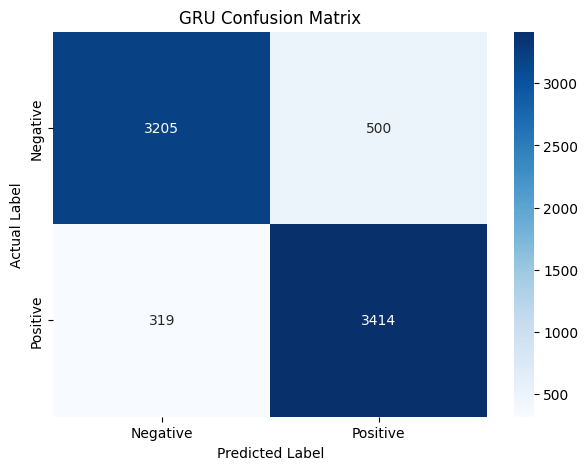

In [54]:

# GRU Confusion Matrix

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title("GRU Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()


 LSTM Confusion Matrix

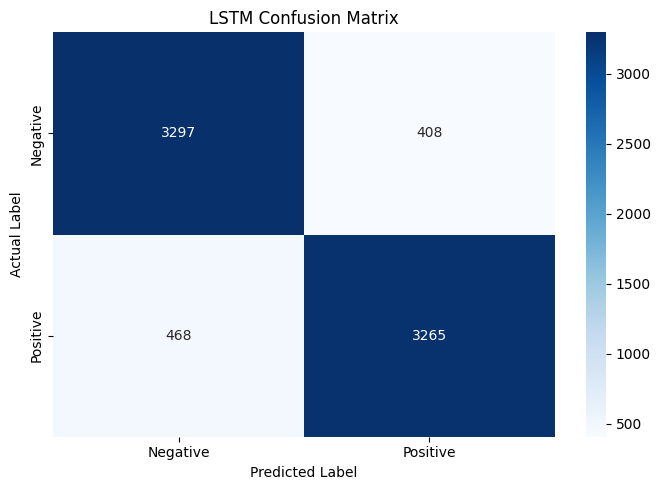

In [55]:
# LSTM Confusion Matrix

cm = confusion_matrix(lstm_y_true, lstm_y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive']
)

plt.title('LSTM Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')

plt.tight_layout()
plt.show()

 GRU Loss Visualization




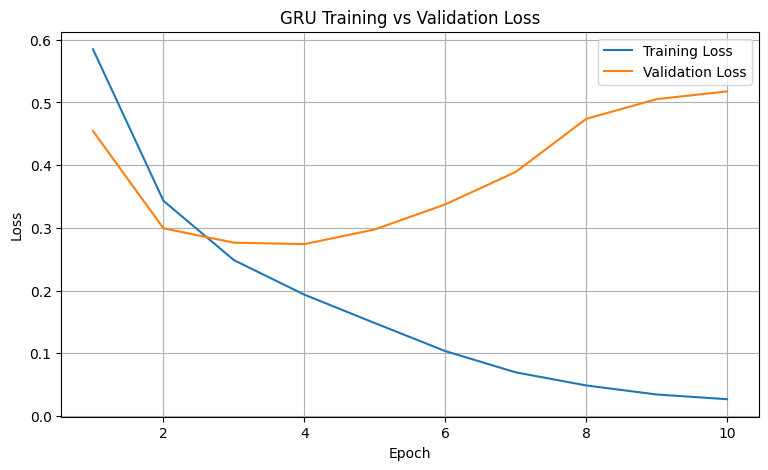

In [56]:

# GRU Loss Visualization

epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(9, 5))

plt.plot(epochs, train_losses, label="Training Loss")
plt.plot(epochs, val_losses, label="Validation Loss")

plt.title("GRU Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)
plt.show()


LSTM Loss Visualization

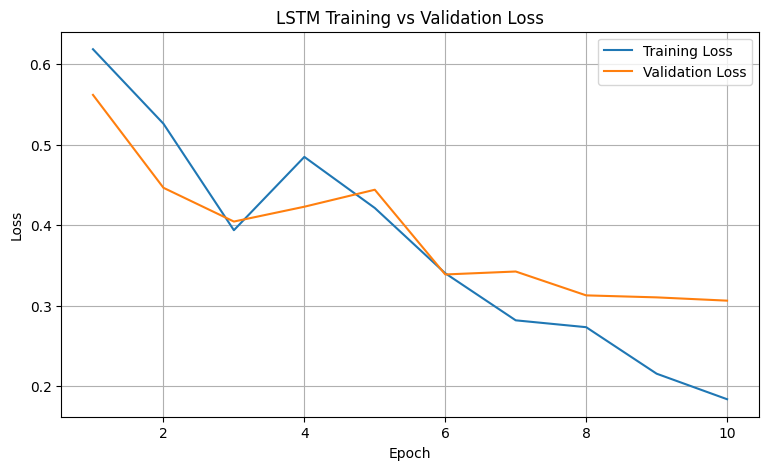

In [57]:

# LSTM Loss Visualization

epochs = range(1, len(lstm_train_losses) + 1)

plt.figure(figsize=(9, 5))

plt.plot(epochs, lstm_train_losses, label="Training Loss")
plt.plot(epochs, lstm_val_losses, label="Validation Loss")

plt.title("LSTM Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)
plt.show()


GRU Accuracy Visualization

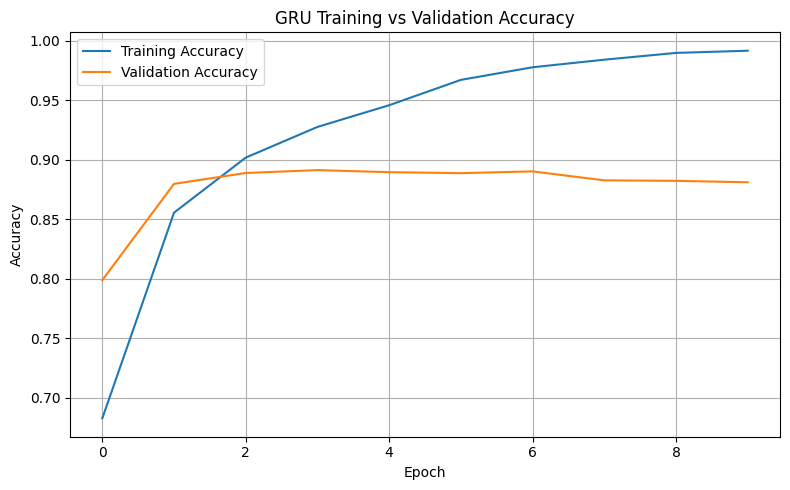

In [46]:
plt.figure(figsize=(8, 5))

plt.plot(train_accuracies, label='Training Accuracy')
plt.plot(val_accuracies, label='Validation Accuracy')

plt.title('GRU Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

LSTM Accuracy Visualization

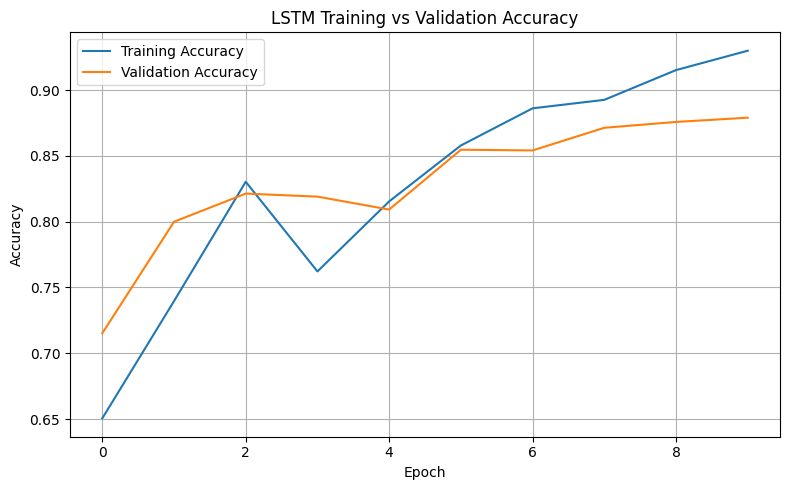

In [47]:
plt.figure(figsize=(8, 5))

plt.plot(lstm_train_accuracies, label='Training Accuracy')
plt.plot(lstm_val_accuracies, label='Validation Accuracy')

plt.title('LSTM Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [48]:
def get_probability(net, text):
    cleaned = clean_text(text)
    if not cleaned:
        return None
    ids = pad_sequence(encode(cleaned))
    x = torch.tensor([ids], dtype=torch.long).to(device)
    net.eval()
    with torch.no_grad():
        return torch.sigmoid(net(x)).item()

def analyze(text):
    if not text or not text.strip():
        raise gr.Error("Please write a movie review first.")
    gru_p = get_probability(model, text)
    lstm_p = get_probability(lstm_model, text)
    if gru_p is None:
        raise gr.Error("Please write the review in English.")
    gru_out = {"Positive": gru_p, "Negative": 1 - gru_p}
    lstm_out = {"Positive": lstm_p, "Negative": 1 - lstm_p}
    return gru_out, lstm_out

In [49]:
tests = [
    "This movie was absolutely wonderful, I loved every minute of it.",
    "Terrible plot and bad acting, a complete waste of time.",
    "It was not good at all."
]
for t in tests:
    print(t)
    print("GRU :", round(get_probability(model, t), 4))
    print("LSTM:", round(get_probability(lstm_model, t), 4))
    print()

This movie was absolutely wonderful, I loved every minute of it.
GRU : 0.9912
LSTM: 0.9902

Terrible plot and bad acting, a complete waste of time.
GRU : 0.003
LSTM: 0.0032

It was not good at all.
GRU : 0.3493
LSTM: 0.3839



In [50]:
print(analyze("It was not good at all."))

({'Positive': 0.3493456542491913, 'Negative': 0.6506543457508087}, {'Positive': 0.38390210270881653, 'Negative': 0.6160978972911835})


In [51]:
demo = gr.Interface(
    fn=analyze,
    inputs=gr.Textbox(lines=6, label="Write a movie review (English)", placeholder="Type your review here..."),
    outputs=[
        gr.Label(num_top_classes=2, label="GRU Prediction"),
        gr.Label(num_top_classes=2, label="LSTM Prediction")
    ],
    title="Movie Review Sentiment Analysis",
    description="Compare GRU and LSTM predictions on IMDB-style movie reviews.",
       examples=[
        ["I expected to hate this movie, but it was not bad at all."],
        ["The acting was great and the music was beautiful, but the story was so boring that I almost fell asleep."],
        ["Oh great, another predictable movie. Just what I needed, two hours of my life wasted."],
        ["Not the worst film I have seen, though I would not call it good either."],
        ["At first I thought it was awful, but by the end I was in tears. A real masterpiece."],
        ["I wanted to like it so much, but nothing worked. Not the script, not the cast, nothing."]
    ],
    flagging_mode="never"
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://26c99eb397f8d51e8d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
